# Análisis y Preparación de Datos — *Metro Interstate Traffic Volume*
## Fase I (Ingesta y Perfilado) y Fase II (Análisis Exploratorio de Datos)

**Dominio:** Transporte y medio ambiente — volumen de tráfico por hora en la interestatal I-94
(Minneapolis–St. Paul, EE. UU.) combinado con variables meteorológicas.

**Fuente:** UCI Machine Learning Repository — *Metro Interstate Traffic Volume Data Set*
(datos de sensores de la MnDOT + OpenWeatherMap, 2012–2018).

**Pregunta de investigación:** ¿Cómo influyen las condiciones meteorológicas y los patrones
temporales (hora, día, feriados) en el volumen de tráfico, y qué impacto tiene la calidad de los
datos sobre esa relación?

> Este notebook cubre las **Fases I y II**. La limpieza (Fase III), transformación (Fase IV) y
> auditoría pre/post (Fase V) se desarrollan en el segundo notebook del proyecto.

## Fase I — Ingesta y Perfilado Inicial

### 0. Entorno y librerías

In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)
print("Versiones -> pandas:", pd.__version__, "| numpy:", np.__version__)

Versiones -> pandas: 3.0.5 | numpy: 2.5.1


### 1.1 Carga de datos (reproducible)
Se descarga el fichero comprimido desde UCI si no está presente localmente y se usa una **ruta
relativa** (`data/...`), de modo que el notebook se ejecute igual en local o en Google Colab.

In [2]:
DATA_URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/00492/Metro_Interstate_Traffic_Volume.csv.gz"
DATA_PATH = "data/Metro_Interstate_Traffic_Volume.csv.gz"

os.makedirs("data", exist_ok=True)
if not os.path.exists(DATA_PATH):
    print("Descargando dataset desde UCI...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH)
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


### 1.2 Dimensiones y tipos de datos

In [3]:
print("Dimensiones (filas, columnas):", df.shape)
print("Nº total de celdas:", df.size)
df.info()

Dimensiones (filas, columnas): (48204, 9)
Nº total de celdas: 433836
<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 3.3 MB


### 1.3 Diccionario de datos

| Variable | Tipo | Unidad / valores | Descripción |
|---|---|---|---|
| `holiday` | Categórica nominal | 11 feriados o nulo | Feriado nacional/regional en esa hora (solo marcado en la hora del feriado). |
| `temp` | Numérica continua | Kelvin (K) | Temperatura media. `0 K` = error de sensor. |
| `rain_1h` | Numérica continua | mm | Lluvia caída en la última hora. |
| `snow_1h` | Numérica continua | mm | Nieve caída en la última hora. |
| `clouds_all` | Numérica discreta | % (0–100) | Porcentaje de nubosidad. |
| `weather_main` | Categórica nominal | 11 categorías | Categoría meteorológica principal (Clouds, Rain, Snow…). |
| `weather_description` | Categórica nominal (texto) | 38 categorías | Descripción textual detallada del clima. |
| `date_time` | Fecha/hora (texto) | `YYYY-MM-DD HH:MM:SS` | Marca temporal de la observación (horaria). |
| `traffic_volume` | Numérica discreta | vehículos/hora | **Variable objetivo:** volumen de tráfico en la I-94. |

### 1.4 Cardinalidad (nº de valores distintos por variable)

In [4]:
cardinalidad = df.nunique().sort_values(ascending=False)
print(cardinalidad)
print("\n'date_time' tiene alta cardinalidad (marca temporal) -> candidata a ingeniería de características.")

date_time              40575
traffic_volume          6704
temp                    5843
rain_1h                  372
clouds_all                60
weather_description       38
snow_1h                   12
holiday                   11
weather_main              11
dtype: int64

'date_time' tiene alta cardinalidad (marca temporal) -> candidata a ingeniería de características.


### 1.5 Matriz diagnóstica de valores nulos
Contamos nulos por columna y su porcentaje, y visualizamos el patrón de ausencia.

                     nulos  % nulos
holiday              48143    99.87
temp                     0     0.00
rain_1h                  0     0.00
snow_1h                  0     0.00
clouds_all               0     0.00
weather_main             0     0.00
weather_description      0     0.00
date_time                0     0.00
traffic_volume           0     0.00


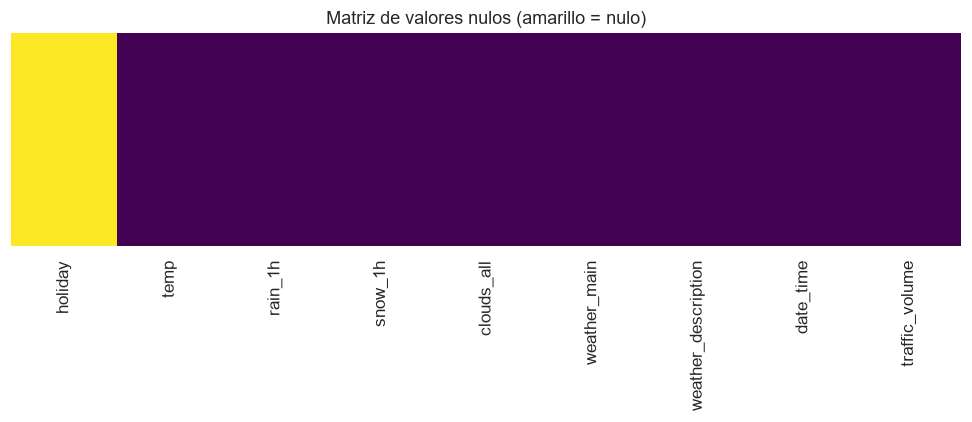

In [5]:
nulos = df.isna().sum()
pct = (nulos / len(df) * 100).round(2)
diag_nulos = pd.DataFrame({"nulos": nulos, "% nulos": pct})
print(diag_nulos)

plt.figure(figsize=(9, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Matriz de valores nulos (amarillo = nulo)")
plt.tight_layout()
plt.show()

**Lectura:** la única columna con nulos es `holiday` (~99,9 %). No es un error de captura:
el dataset **solo marca el feriado en la hora exacta** y deja el resto vacío. Por tanto, un
`dropna()` ciego eliminaría casi todo el dataset — el tratamiento correcto (Fase III) es
**rellenar con una categoría explícita** (p. ej. `"None"`), no imputar ni borrar.

### 1.6 Registros duplicados

In [6]:
print("Duplicados exactos (todas las columnas):", df.duplicated().sum())
print("Duplicados por marca temporal (date_time):", df.duplicated(subset='date_time').sum())

Duplicados exactos (todas las columnas): 17
Duplicados por marca temporal (date_time): 7629


Hay **17 duplicados exactos** y varias marcas temporales repetidas (dos registros meteorológicos
para la misma hora). Ambos se tratarán en la Fase III (eliminación de duplicados exactos y
resolución de conflictos temporales).

### 1.7 Estadística descriptiva inicial

In [7]:
num_cols = ['temp', 'rain_1h', 'snow_1h', 'clouds_all', 'traffic_volume']
cat_cols = ['holiday', 'weather_main', 'weather_description']

print("=== Variables numéricas ===")
display(df[num_cols].describe().T)

print("\n=== Variables categóricas ===")
display(df[cat_cols].describe().T)

=== Variables numéricas ===


,count,mean,std,min,25%,50%,75%,max
temp,48204.0,281.205870,13.338232,0.0,272.16,282.45,291.806,310.07
rain_1h,48204.0,0.334264,44.789133,0.0,0.00,0.00,0.000,9831.30
snow_1h,48204.0,0.000222,0.008168,0.0,0.00,0.00,0.000,0.51
clouds_all,48204.0,49.362231,39.015750,0.0,1.00,64.00,90.000,100.00
traffic_volume,48204.0,3259.818355,1986.860670,0.0,1193.00,3380.00,4933.000,7280.00



=== Variables categóricas ===


,count,unique,top,freq
holiday,61,11,Labor Day,7
weather_main,48204,11,Clouds,15164
weather_description,48204,38,sky is clear,11665


**Diagnóstico inicial de calidad (resumen Fase I):**

- **Volumen:** 48 204 filas × 9 columnas (cumple > 1 000 filas y ≥ 8 columnas).
- **Heterogeneidad:** 5 numéricas + 3 categóricas + 1 temporal.
- **Nulos:** solo `holiday` (patrón estructural, no aleatorio).
- **Outliers evidentes:** `temp` mínima = **0 K** (imposible físicamente) y `rain_1h` máxima =
  **9831 mm** (imposible en 1 hora) → errores de sensor a tratar en Fase III.
- **Duplicados:** 17 exactos.
- **Alta cardinalidad temporal:** `date_time` → base para variables derivadas.

## Fase II — Análisis Exploratorio de Datos (EDA)

### 2.1 Preguntas analíticas
1. ¿Cómo se distribuyen las variables numéricas? ¿Presentan asimetría o colas pesadas que exijan
   escalado robusto?
2. ¿Qué variables meteorológicas se asocian con el volumen de tráfico?
3. ¿Existen patrones temporales (hora del día, día de la semana) en el tráfico?
4. ¿Qué diferencia hay entre correlaciones de Pearson (lineal) y Spearman (monótona) y qué revela
   sobre la influencia de los outliers?

### 2.2 Distribuciones univariadas de variables numéricas (histograma + KDE)

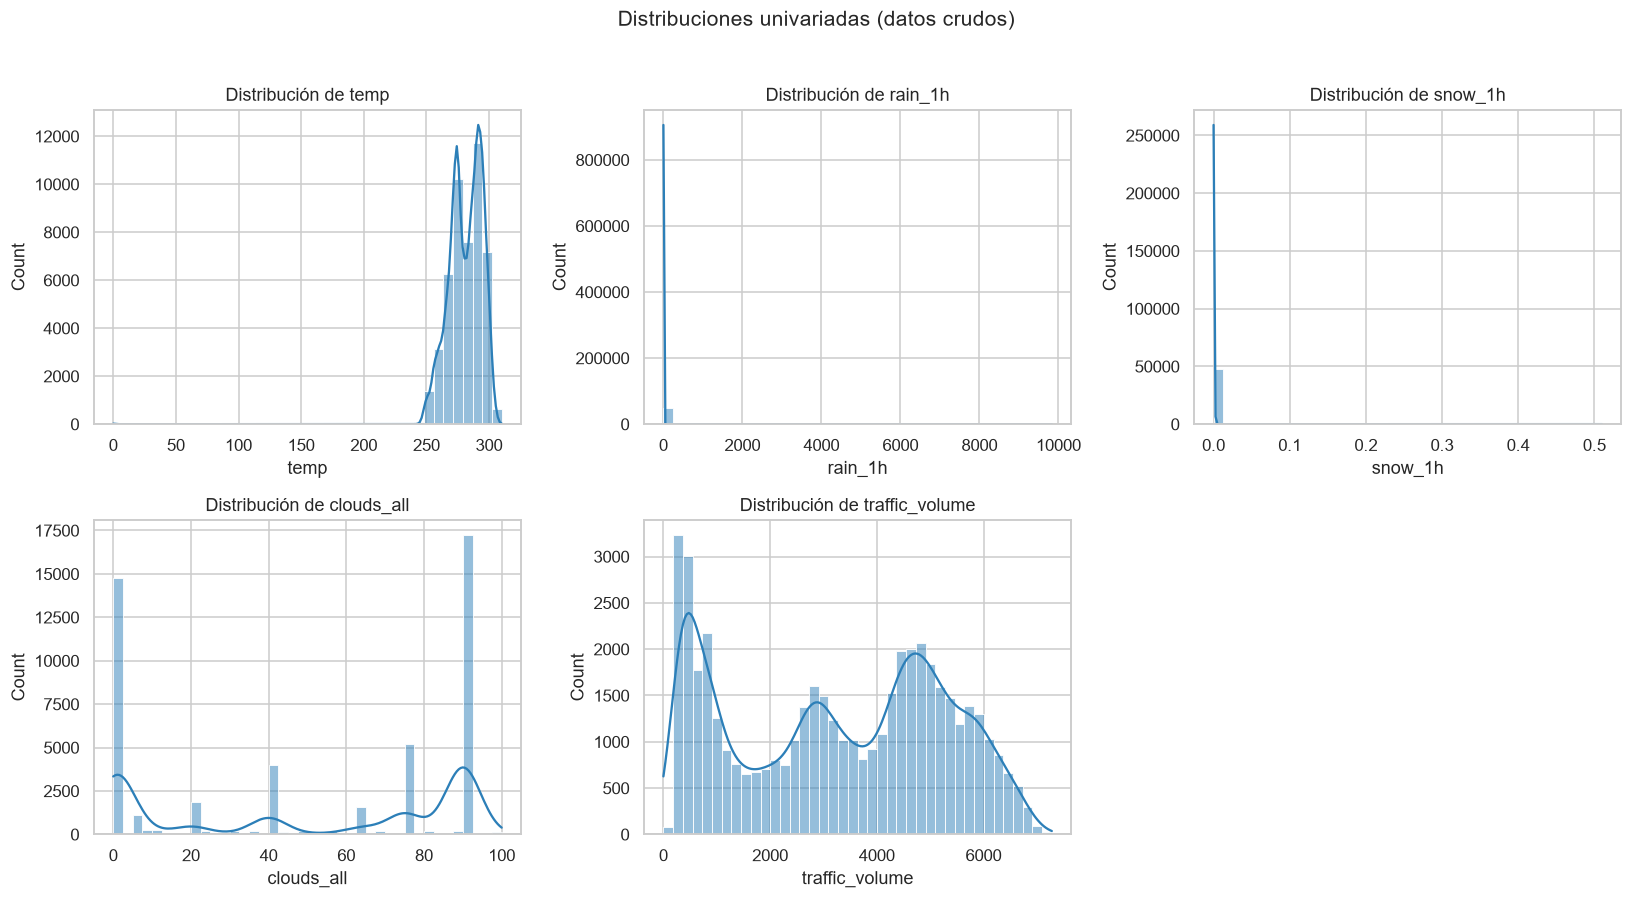

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, ax=ax, bins=40, color="#2c7fb8")
    ax.set_title(f"Distribución de {col}")
axes.ravel()[-1].axis("off")
fig.suptitle("Distribuciones univariadas (datos crudos)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Se observa fuerte **asimetría** en `rain_1h` y `snow_1h` (casi todo en cero con outliers
extremos) y en `traffic_volume` una distribución **bimodal** (horas valle vs. horas pico).

### 2.3 Distribuciones de variables categóricas

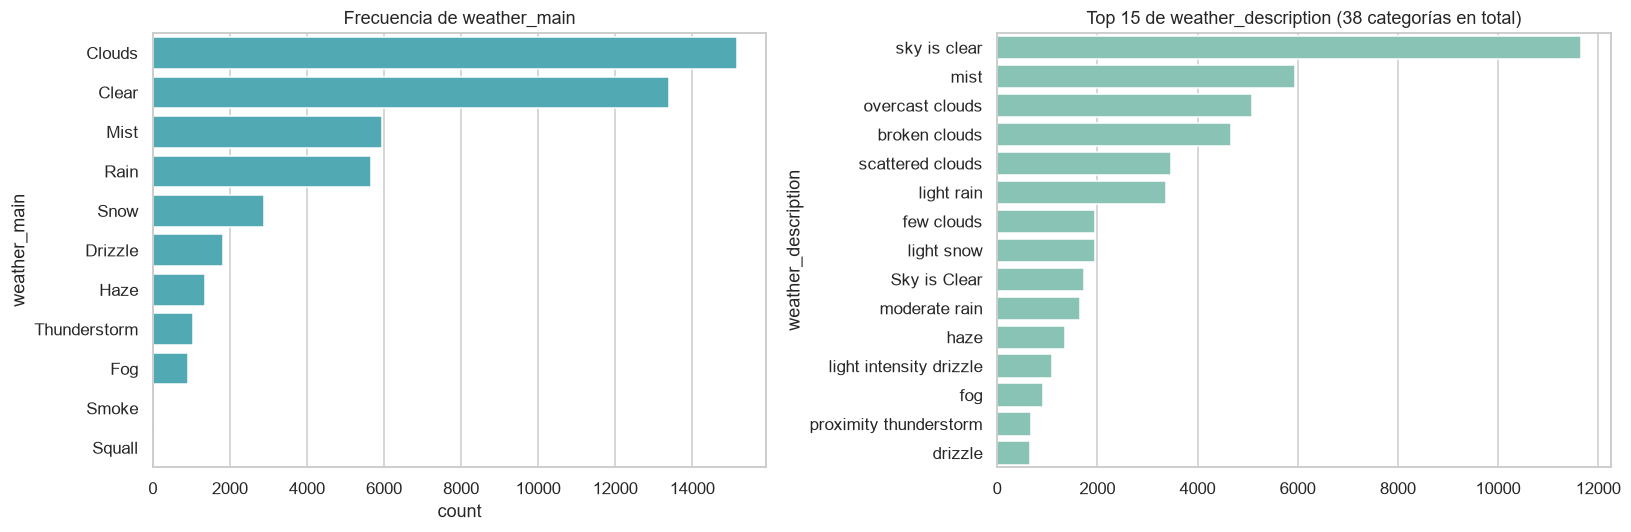

Feriados más frecuentes (holiday, excluyendo nulos):
holiday
Labor Day                    7
Thanksgiving Day             6
Christmas Day                6
New Years Day                6
Martin Luther King Jr Day    6
Columbus Day                 5
Veterans Day                 5
Washingtons Birthday         5
Memorial Day                 5
Independence Day             5
State Fair                   5
Name: count, dtype: int64


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, y="weather_main",
              order=df["weather_main"].value_counts().index, ax=axes[0], color="#41b6c4")
axes[0].set_title("Frecuencia de weather_main")

top_desc = df["weather_description"].value_counts().head(15)
sns.barplot(x=top_desc.values, y=top_desc.index, ax=axes[1], color="#7fcdbb")
axes[1].set_title("Top 15 de weather_description (38 categorías en total)")
plt.tight_layout()
plt.show()

print("Feriados más frecuentes (holiday, excluyendo nulos):")
print(df["holiday"].value_counts())

`weather_description` tiene **38 categorías muy granulares y solapadas** (p. ej. *light rain*,
*proximity shower rain*, *heavy intensity rain*). Esto es una **inconsistencia textual** típica que
se consolidará/estandarizará en la Fase III.

### 2.4 Detección visual de outliers (boxplots)

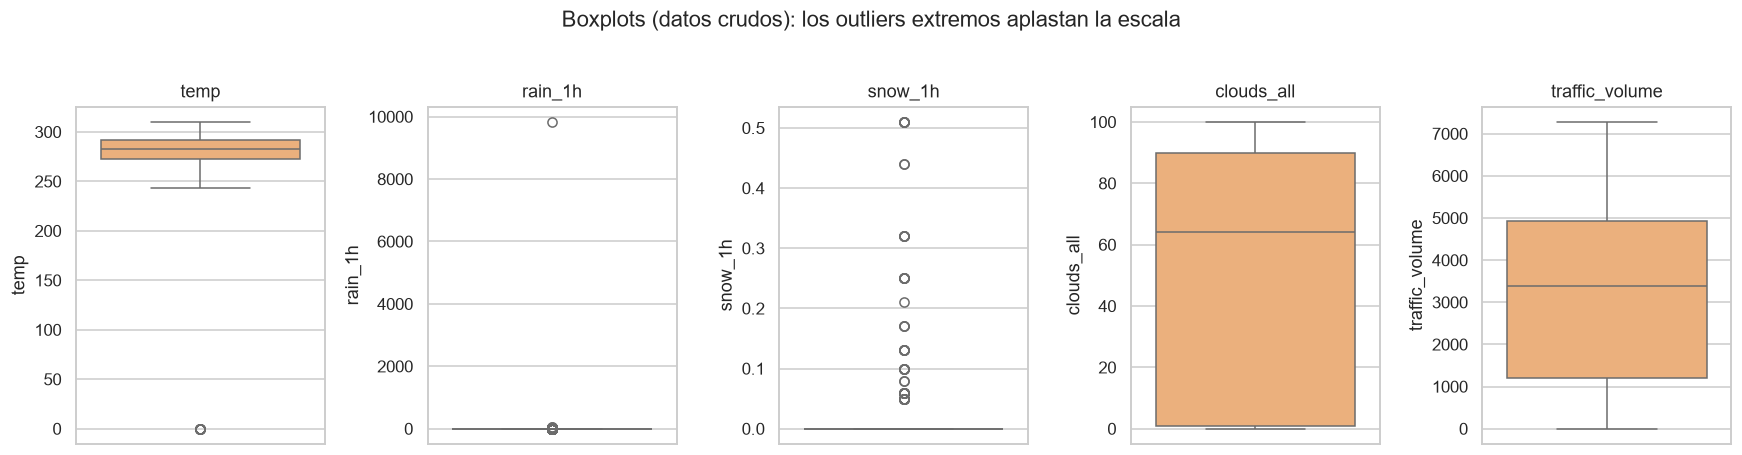

Evidencia cuantitativa de outliers:
 - temp == 0 K (sensor roto): 10 filas
 - rain_1h > 1000 mm (imposible): 1 fila(s), máx = 9831.3


In [10]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="#fdae6b")
    ax.set_title(col)
fig.suptitle("Boxplots (datos crudos): los outliers extremos aplastan la escala", y=1.03)
plt.tight_layout()
plt.show()

print("Evidencia cuantitativa de outliers:")
print(" - temp == 0 K (sensor roto):", int((df['temp'] == 0).sum()), "filas")
print(" - rain_1h > 1000 mm (imposible):", int((df['rain_1h'] > 1000).sum()), "fila(s), máx =", df['rain_1h'].max())

### 2.5 Asimetría (*skewness*) y curtosis — línea base pre-procesamiento
Estas métricas se compararán en la **Fase V** (auditoría pre/post) para evidenciar el efecto del
pipeline de limpieza y transformación.

In [11]:
forma = pd.DataFrame({
    "skewness": df[num_cols].skew(),
    "kurtosis": df[num_cols].kurtosis(),
}).round(3)
forma

,skewness,kurtosis
temp,-2.247,39.915
rain_1h,219.389,48155.627
snow_1h,48.367,2620.466
clouds_all,-0.197,-1.742
traffic_volume,-0.089,-1.309


### 2.6 Correlaciones: Pearson (lineal) vs. Spearman (monótona)

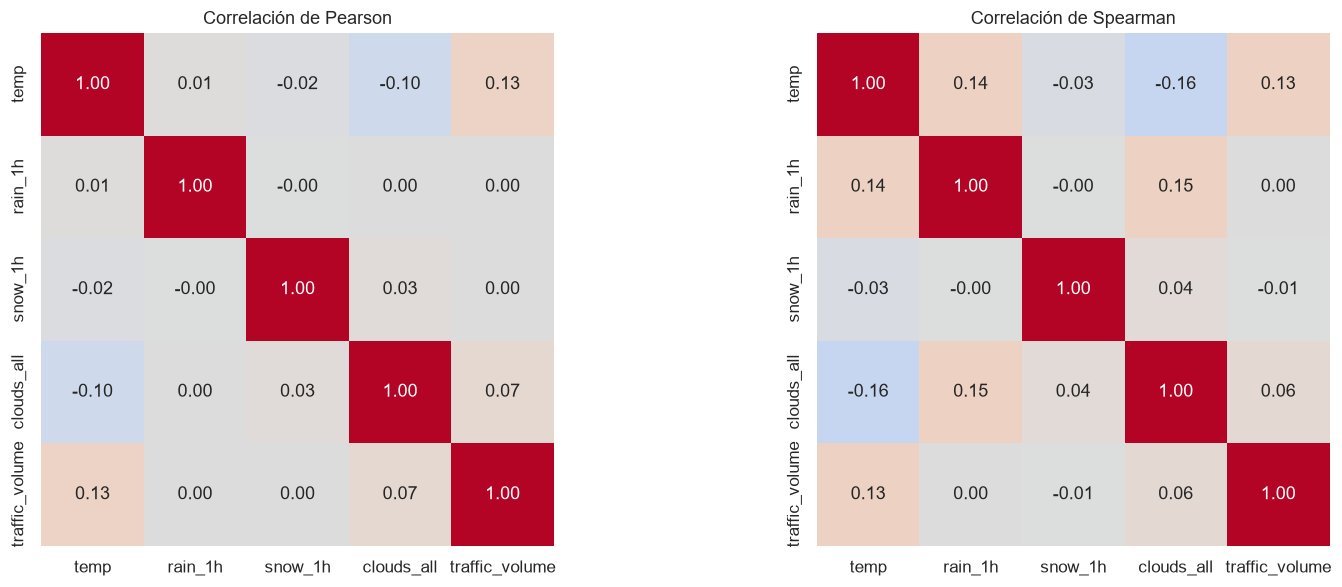

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    corr = df[num_cols].corr(method=metodo)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
                vmin=-1, vmax=1, square=True, ax=ax, cbar=False)
    ax.set_title(f"Correlación de {metodo.capitalize()}")
plt.tight_layout()
plt.show()

La diferencia entre ambas matrices es reveladora: **Spearman** (basada en rangos) es **robusta a
los outliers** de `rain_1h`/`snow_1h`, mientras que **Pearson** se ve distorsionada por ellos.
Esto justifica más adelante el uso de un **RobustScaler** para las variables con colas pesadas.

### 2.7 Relaciones clave con la variable objetivo (bivariado)

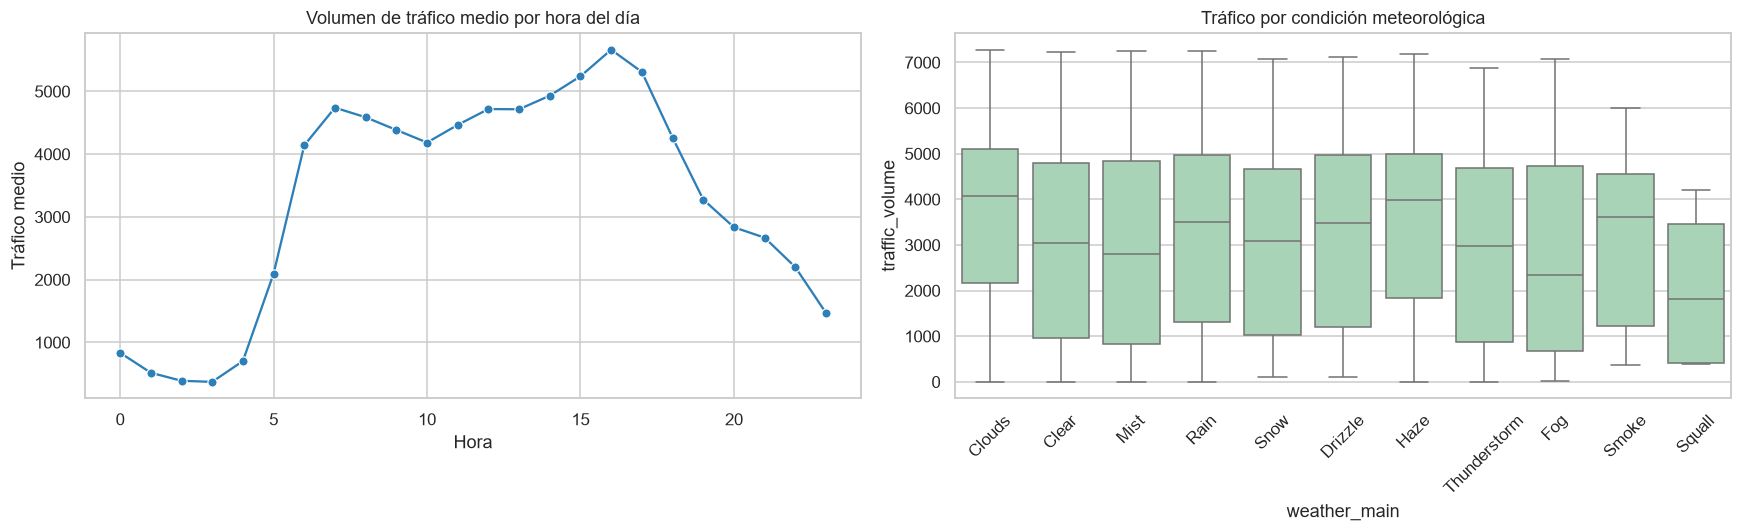

In [13]:
# Extracción temporal SOLO para el EDA (la ingeniería formal se hace en la Fase IV)
tmp = df.copy()
tmp["date_time"] = pd.to_datetime(tmp["date_time"], errors="coerce")
tmp["hora"] = tmp["date_time"].dt.hour
tmp["dia_semana"] = tmp["date_time"].dt.day_name()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.lineplot(data=tmp.groupby("hora")["traffic_volume"].mean().reset_index(),
             x="hora", y="traffic_volume", marker="o", ax=axes[0], color="#2c7fb8")
axes[0].set_title("Volumen de tráfico medio por hora del día")
axes[0].set_xlabel("Hora"); axes[0].set_ylabel("Tráfico medio")

sns.boxplot(data=tmp, x="weather_main", y="traffic_volume",
            order=tmp["weather_main"].value_counts().index, ax=axes[1], color="#a1dab4")
axes[1].set_title("Tráfico por condición meteorológica")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Hallazgos preliminares (cierre Fase II):**

- El tráfico muestra un claro patrón **bimodal por hora** (picos ~07:00 y ~16:00), confirmando la
  importancia de derivar la variable *hora* y *hora pico*.
- Las condiciones meteorológicas modifican la mediana del tráfico, aunque el efecto de la hora es
  dominante.
- La fuerte asimetría y los outliers extremos de las variables de precipitación anticipan la
  necesidad de **escalado robusto** y **tratamiento de outliers** en las fases siguientes.

➡️ **Siguiente entregable:** Notebook de Fases III–V (limpieza, transformación, ingeniería de
características y auditoría pre/post).